<a href="https://colab.research.google.com/github/RiyaGupta07/MACHINE_FAULT_PREDICTION/blob/main/MACHINE_FAULT_PREDICTION.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

print("Machine Fault Prediction Project Started!")

Machine Fault Prediction Project Started!


In [5]:

# STEP 2: Generate Machine Dataset

import numpy as np
import pandas as pd

# Generate 3000 records
np.random.seed(42)

n = 3000

temperature = np.random.uniform(30, 110, n)
vibration = np.random.uniform(1, 12, n)
rpm = np.random.uniform(400, 3200, n)
operating_hours = np.random.uniform(1, 24, n)

# Create machine condition labels
def predict_condition(temp, vib, rpm):

    if temp > 90 or vib > 8 or rpm < 500 or rpm > 3000:
        return "Fault"

    elif temp > 75 or vib > 5 or rpm < 800 or rpm > 2500:
        return "Warning"

    else:
        return "Normal"

# Create dataset
data = pd.DataFrame({
    "Temperature": temperature,
    "Vibration": vibration,
    "RPM": rpm,
    "Operating_Hours": operating_hours
})

data["Machine_Status"] = [
    predict_condition(t, v, r)
    for t, v, r in zip(temperature, vibration, rpm)
]

# Save dataset
data.to_csv("machine_data.csv", index=False)

print("Dataset created successfully!")
print("Total Records:", len(data))

data.head(10)


Dataset created successfully!
Total Records: 3000


,Temperature,Vibration,RPM,Operating_Hours,Machine_Status
0,59.963210,8.399733,2215.119471,22.012294,Fault
1,106.057145,9.763495,882.681814,13.083291,Fault
2,88.559515,3.755147,2842.704777,17.672936,Warning
3,77.892679,7.873615,2116.725469,11.029111,Warning
4,42.481491,7.289206,840.170874,15.490795,Warning
5,42.479562,10.161134,3094.546561,8.833247,Fault
6,34.646689,10.966958,1851.423297,7.926657,Fault
7,99.294092,1.133724,604.115665,14.299285,Fault
8,78.089201,8.414219,2155.132132,12.456983,Fault
9,86.645806,1.570194,1108.956940,14.329336,Warning


In [ ]:

# STEP 3: Exploratory Data Analysis

# 1. Dataset information
print("Dataset Information:")
data.info()

# 2. Statistical summary
print("\nStatistical Summary:")
display(data.describe())

# 3. Check missing values
print("\nMissing Values:")
print(data.isnull().sum())

# 4. Count machine conditions
print("\nMachine Status Distribution:")
print(data["Machine_Status"].value_counts())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Temperature      3000 non-null   float64
 1   Vibration        3000 non-null   float64
 2   RPM              3000 non-null   float64
 3   Operating_Hours  3000 non-null   float64
 4   Machine_Status   3000 non-null   object 
dtypes: float64(4), object(1)
memory usage: 117.3+ KB

Statistical Summary:


,Temperature,Vibration,RPM,Operating_Hours
count,3000.000000,3000.000000,3000.000000,3000.000000
mean,69.991456,6.437464,1764.697739,12.559327
std,23.332515,3.161661,799.637269,6.629791
min,30.000931,1.000338,400.674813,1.001215
25%,49.664446,3.703003,1076.107869,6.854066
50%,70.428300,6.368428,1750.883327,12.477719
75%,90.346756,9.124494,2440.301186,18.368570
max,109.977414,11.995135,3198.489907,23.992484



Missing Values:
Temperature        0
Vibration          0
RPM                0
Operating_Hours    0
Machine_Status     0
dtype: int64

Machine Status Distribution:
Machine_Status
Fault      1692
Warning     925
Normal      383
Name: count, dtype: int64


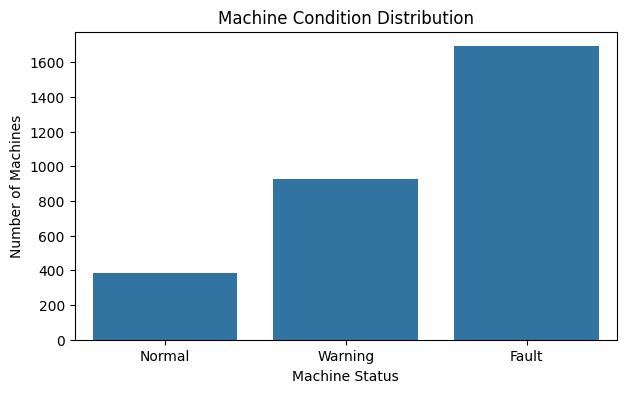

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

# Machine status distribution
plt.figure(figsize=(7, 4))

sns.countplot(
    data=data,
    x="Machine_Status",
    order=["Normal", "Warning", "Fault"]
)

plt.title("Machine Condition Distribution")
plt.xlabel("Machine Status")
plt.ylabel("Number of Machines")
plt.show()


In [ ]:

# STEP 4: Data Preparation

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Select input features
X = data[[
    "Temperature",
    "Vibration",
    "RPM",
    "Operating_Hours"
]]

# Select target variable
y = data["Machine_Status"]

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 2400
Testing records: 600


In [ ]:

# STEP 5: Train Machine Learning Model

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

print("Machine Learning Model Trained Successfully!")


Machine Learning Model Trained Successfully!


In [ ]:

# STEP 6: Model Evaluation

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Model Accuracy: 99.83 %

Classification Report:
              precision    recall  f1-score   support

       Fault       1.00      1.00      1.00       338
      Normal       0.99      1.00      0.99        77
     Warning       1.00      0.99      1.00       185

    accuracy                           1.00       600
   macro avg       1.00      1.00      1.00       600
weighted avg       1.00      1.00      1.00       600



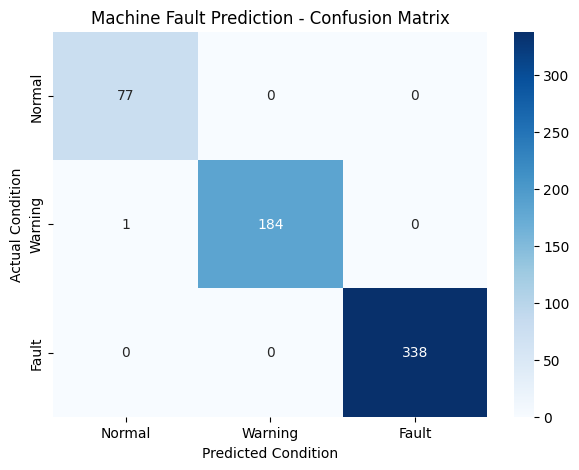

In [ ]:

# Confusion Matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Normal", "Warning", "Fault"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Warning", "Fault"],
    yticklabels=["Normal", "Warning", "Fault"]
)

plt.xlabel("Predicted Condition")
plt.ylabel("Actual Condition")
plt.title("Machine Fault Prediction - Confusion Matrix")

plt.show()


In [ ]:

# STEP 7: Interactive Machine Prediction

import ipywidgets as widgets
from IPython.display import display, clear_output

# Input sliders
temp_slider = widgets.FloatSlider(
    value=50, min=30, max=110,
    description="Temperature:"
)

vibration_slider = widgets.FloatSlider(
    value=3, min=1, max=12,
    description="Vibration:"
)

rpm_slider = widgets.IntSlider(
    value=1500, min=400, max=3200,
    description="RPM:"
)

hours_slider = widgets.IntSlider(
    value=8, min=1, max=24,
    description="Hours:"
)

button = widgets.Button(
    description="Predict Machine Condition",
    button_style="success"
)

output = widgets.Output()

def predict_machine(b):
    with output:
        clear_output()

        sample = pd.DataFrame([{
            "Temperature": temp_slider.value,
            "Vibration": vibration_slider.value,
            "RPM": rpm_slider.value,
            "Operating_Hours": hours_slider.value
        }])

        result = model.predict(sample)[0]

        print("MACHINE HEALTH REPORT")
        print("---------------------")
        print("Temperature:", temp_slider.value, "°C")
        print("Vibration:", vibration_slider.value)
        print("RPM:", rpm_slider.value)
        print("Operating Hours:", hours_slider.value)

        print("\nPredicted Condition:", result)

        if result == "Normal":
            print("Machine is operating normally.")
        elif result == "Warning":
            print("Warning! Check machine condition.")
        else:
            print("Fault detected! Maintenance required.")

button.on_click(predict_machine)

display(temp_slider, vibration_slider,
        rpm_slider, hours_slider, button, output)


FloatSlider(value=50.0, description='Temperature:', max=110.0, min=30.0)

FloatSlider(value=3.0, description='Vibration:', max=12.0, min=1.0)

IntSlider(value=1500, description='RPM:', max=3200, min=400)

IntSlider(value=8, description='Hours:', max=24, min=1)

Button(button_style='success', description='Predict Machine Condition', style=ButtonStyle())

Output()

In [ ]:

import joblib

# Save the trained Random Forest model
joblib.dump(model, "machine_fault_model.pkl")

print("Machine Learning Model Saved Successfully!")


Machine Learning Model Saved Successfully!


In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib

st.set_page_config(
    page_title="Machine Health Monitor",
    page_icon="⚙️",
    layout="wide"
)

model = joblib.load("machine_fault_model.pkl")

st.title("⚙️ Industrial Machine Health Monitor")
st.caption("AI-Based Predictive Maintenance System")

st.divider()

st.subheader("Machine Operating Parameters")

c1, c2 = st.columns(2)

with c1:
    temp = st.slider("Temperature (°C)", 30, 110, 50)
    vibration = st.slider("Vibration (mm/s)", 1.0, 12.0, 3.0)

with c2:
    rpm = st.slider("Motor Speed (RPM)", 400, 3200, 1500)
    hours = st.slider("Operating Hours", 1, 24, 8)

if st.button("🔍 Predict Machine Condition", use_container_width=True):

    sample = pd.DataFrame([{
        "Temperature": temp,
        "Vibration": vibration,
        "RPM": rpm,
        "Operating_Hours": hours
    }])

    result = model.predict(sample)[0]

    st.divider()
    st.subheader("Machine Health Report")

    a, b, c = st.columns(3)

    a.metric("Temperature", f"{temp} °C")
    b.metric("Vibration", f"{vibration} mm/s")
    c.metric("Motor Speed", f"{rpm} RPM")

    if result == "Normal":
        st.success("NORMAL - Machine is operating normally.")
        st.write("Recommendation: Continue regular monitoring.")

    elif result == "Warning":
        st.warning("WARNING - Abnormal readings detected.")
        st.write("Recommendation: Inspect the machine and schedule maintenance.")

    else:
        st.error("FAULT DETECTED - Maintenance required!")
        st.write("Recommendation: Stop and inspect the machine before further operation.")

st.divider()
st.caption("Prototype using simulated sensor data and Random Forest ML.")

Writing app.py


In [ ]:
from google.colab import files

files.download("machine_fault_model.pkl")
files.download("app.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>